In [1]:
%pip install darts

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 70.0/70.0 kB 3.1 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 59.4/59.4 kB 4.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 907.7/907.7 kB 36.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 417.4/417.4 kB 23.7 MB/s eta 0:00:00


In [2]:
import warnings, json, os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from darts import TimeSeries
from darts.dataprocessing.transformers import Scaler
from darts.models import (RandomForest, LinearRegressionModel, LightGBMModel,
                          AutoARIMA, NBEATSModel)
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

warnings.filterwarnings("ignore")

In [3]:
SEED = 0
DATASET_NAME = "daily_waste_output_Boralasgamuwa"
DATA_FILE    = "daily_waste_output_Boralasgamuwa"        # output of the Moratuwa imputation notebook
TEST_START   = "2016-05-01"
OUTPUT_DIR   = f"results_{DATASET_NAME}"
os.makedirs(OUTPUT_DIR, exist_ok=True)

In [4]:
df = pd.read_csv('daily_waste_output_Boralasgamuwa.csv')

In [5]:
df.head(5)

,ticket_date,net_weight_kg
0,2012-01-01 00:00:00+00:00,17340.0
1,2012-01-02 00:00:00+00:00,25980.0
2,2012-01-03 00:00:00+00:00,29220.0
3,2012-01-04 00:00:00+00:00,7450.0
4,2012-01-05 00:00:00+00:00,10520.0


In [6]:
df.shape

(2557, 2)

In [7]:
df["ticket_date"] = pd.to_datetime(df["ticket_date"], utc=True).dt.tz_localize(None)

In [8]:
df = df[["ticket_date", "net_weight_kg"]].sort_values("ticket_date").reset_index(drop=True)

In [9]:
series = TimeSeries.from_dataframe(df, time_col="ticket_date", value_cols="net_weight_kg", freq="D")

In [10]:
train_series, test_series = series.split_before(pd.Timestamp(TEST_START))
print("Train days:", len(train_series), "| Test days:", len(test_series))

Train days: 1582 | Test days: 975


In [11]:
def scores(actual, pred):
    out = {"rmse": float(np.sqrt(mean_squared_error(actual, pred))),
           "mae":  float(mean_absolute_error(actual, pred)),
           "r2":   float(r2_score(actual, pred))}
    if np.all(actual != 0):                       # MAPE breaks when a real value is 0
        out["mape_%"] = float(np.mean(np.abs((actual - pred) / actual)) * 100)
    return out

def forecast(model, train, n_days):
    scaler = Scaler()                             # min-max, fitted on the training part only
    model.fit(scaler.fit_transform(train))
    pred = scaler.inverse_transform(model.predict(n=n_days))
    return pred.values().flatten()

all_results, all_preds = {}, {}

def run_model(label, make_model, grid):
    """grid = list of settings dictionaries. make_model(settings) returns a new model."""
    horizon = len(test_series)
    train_main, val_series = train_series[:-horizon], train_series[-horizon:]
    val_actual = val_series.values().flatten()

    #  pick the best one on the validation block (not on the test period)
    best_params, best_err = None, np.inf
    for params in grid:
        try:
            err = float(np.sqrt(mean_squared_error(
                val_actual, forecast(make_model(params), train_main, horizon))))
            print(label, params, "-> validation RMSE", round(err, 1))
            if err < best_err:
                best_params, best_err = params, err
        except Exception as e:
            print("Failed:", label, params, "|", str(e)[:100])
    if best_params is None:
        raise ValueError(f"All settings failed for {label}")

    # refit on the full training part, forecast the test period once
    actual = test_series.values().flatten()
    pred = forecast(make_model(best_params), train_series, horizon)

    name = label + "_" + "_".join(f"{k}-{v}" for k, v in best_params.items())
    all_results[label] = {"model_name": name, **scores(actual, pred)}
    all_preds[label] = pred
    print("DONE:", name, all_results[label], "\n")

# Random Forest

In [12]:
grid = [{"lags": l, "n_estimators": n, "max_depth": d}
        for l in [7, 28, 60] for n in [10, 100] for d in [4, 8]]

run_model("rf",
          lambda p: RandomForest(lags=p["lags"], n_estimators=p["n_estimators"],
                                 max_depth=p["max_depth"], random_state=SEED),
          grid)

rf {'lags': 7, 'n_estimators': 10, 'max_depth': 4} -> validation RMSE 10100.8


rf {'lags': 7, 'n_estimators': 10, 'max_depth': 8} -> validation RMSE 10931.0


rf {'lags': 7, 'n_estimators': 100, 'max_depth': 4} -> validation RMSE 9991.5


rf {'lags': 7, 'n_estimators': 100, 'max_depth': 8} -> validation RMSE 10668.2


rf {'lags': 28, 'n_estimators': 10, 'max_depth': 4} -> validation RMSE 9387.7


...

rf {'lags': 28, 'n_estimators': 100, 'max_depth': 8} -> validation RMSE 9988.1


rf {'lags': 60, 'n_estimators': 10, 'max_depth': 4} -> validation RMSE 9281.2


rf {'lags': 60, 'n_estimators': 10, 'max_depth': 8} -> validation RMSE 9244.4


rf {'lags': 60, 'n_estimators': 100, 'max_depth': 4} -> validation RMSE 9295.9


rf {'lags': 60, 'n_estimators': 100, 'max_depth': 8} -> validation RMSE 9233.8
DONE: rf_lags-60_n_estimators-100_max_depth-8 {'model_name': 'rf_lags-60_n_estimators-100_max_depth-8', 'rmse': 8311.366796860852, 'mae': 6338.642074493778, 'r2': 0.012707645086232677} 



## Linear Regression

In [13]:
grid = [{"lags": l} for l in [7, 14, 28, 60, 90]]

run_model("lr", lambda p: LinearRegressionModel(lags=p["lags"]), grid)

lr {'lags': 7} -> validation RMSE 10001.5
lr {'lags': 14} -> validation RMSE 9980.6
lr {'lags': 28} -> validation RMSE 9871.7
lr {'lags': 60} -> validation RMSE 9757.9
lr {'lags': 90} -> validation RMSE 9820.7
DONE: lr_lags-60 {'model_name': 'lr_lags-60', 'rmse': 8284.1864038056, 'mae': 6355.899987207294, 'r2': 0.019154506623318968} 



## LIGHT GBM

In [14]:
grid = [{"lags": l} for l in [7, 14, 28, 60, 90]]

run_model("lgbm",
          lambda p: LightGBMModel(lags=p["lags"], random_state=SEED, verbose=-1),
          grid)

lgbm {'lags': 7} -> validation RMSE 11450.6
lgbm {'lags': 14} -> validation RMSE 11276.3
lgbm {'lags': 28} -> validation RMSE 11883.0
lgbm {'lags': 60} -> validation RMSE 12055.9
lgbm {'lags': 90} -> validation RMSE 12541.3
DONE: lgbm_lags-14 {'model_name': 'lgbm_lags-14', 'rmse': 10195.537265382649, 'mae': 8293.22649856524, 'r2': -0.48566574106345417} 



## Compare the models

,rmse,mae,r2
baseline: weekday average,7930.22,5943.40,0.10
lr,8284.19,6355.90,0.02
rf,8311.37,6338.64,0.01
baseline: mean of training,8387.85,6472.74,-0.01
lgbm,10195.54,8293.23,-0.49
baseline: same weekday last week,11467.60,8962.02,-0.88


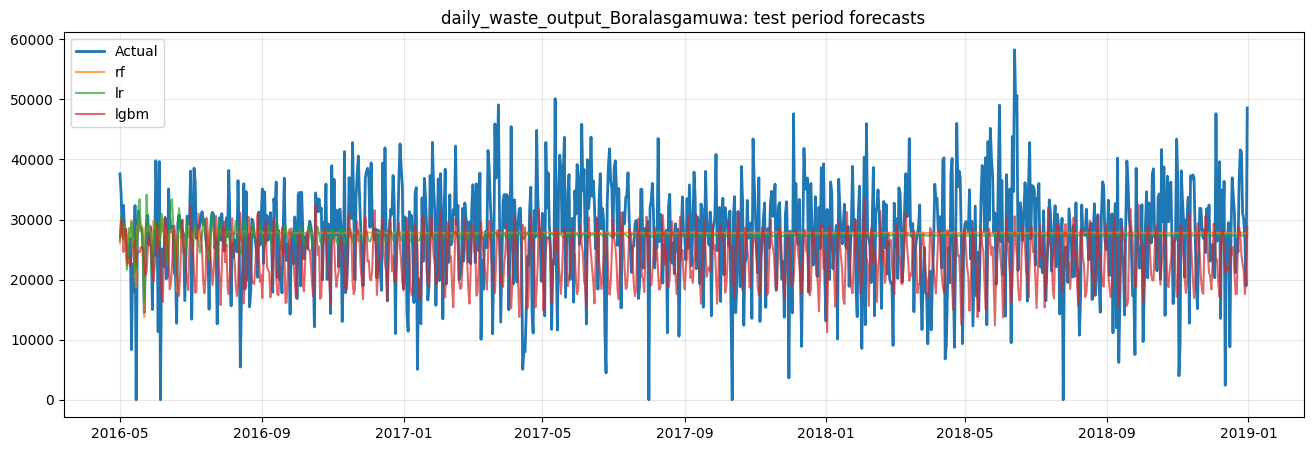

In [18]:
actual = test_series.values().flatten()
n = len(actual)
train_vals = train_series.values().flatten()
weekday_mean = pd.Series(train_vals).groupby(train_series.time_index.dayofweek.to_numpy()).mean()

baselines = {
    "baseline: mean of training": np.full(n, train_vals.mean()),
    "baseline: same weekday last week": np.tile(train_vals[-7:], n // 7 + 1)[:n],
    "baseline: weekday average": weekday_mean.reindex(test_series.time_index.dayofweek).to_numpy(),
}

rows = {label: {k: v for k, v in r.items() if k != "model_name"} for label, r in all_results.items()}
for name, p in baselines.items():
    rows[name] = scores(actual, p)

table = pd.DataFrame(rows).T.sort_values("rmse")
display(table.round(2))
table.to_csv(f"{OUTPUT_DIR}/all_models_test_scores.csv")

plt.figure(figsize=(16, 5))
plt.plot(test_series.time_index, actual, label="Actual", linewidth=2)
for label, p in all_preds.items():
    plt.plot(test_series.time_index, p, label=label, alpha=0.7)
plt.legend(); plt.grid(alpha=0.3); plt.title(f"{DATASET_NAME}: test period forecasts")
plt.savefig(f"{OUTPUT_DIR}/all_models_forecast.png", dpi=150)
plt.show()

In [19]:
print(list(all_results.keys()))
   for k, v in all_results.items():
       print(k, "->", v["model_name"])
   print("Zero days in test:", int((actual == 0).sum()))

['rf', 'lr', 'lgbm']
rf -> rf_lags-60_n_estimators-100_max_depth-8
lr -> lr_lags-60
lgbm -> lgbm_lags-14
Zero days in test: 5
